# Day 02 – Data Understanding
## Holistic Data Preparer | Fintech – Customer Credit Risk Prediction

## 1. Project setup and library imports

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

# Resolve the project root whether the notebook is launched from the project root
# or from the notebooks directory.
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR if (CURRENT_DIR / "data").exists() else CURRENT_DIR.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
REPORTS_DIR = PROJECT_ROOT / "reports"

for folder in [RAW_DIR, INTERIM_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Raw data folder:", RAW_DIR.resolve())

Project root: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\notebooks
Raw data folder: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\notebooks\data\raw


## 2. Load the Customer Credit Risk dataset

In [2]:
EXPECTED_COLUMNS = {
    "customer_id", "age", "gender", "region", "education_level",
    "employment_type", "annual_income", "loan_amount", "loan_purpose",
    "credit_score", "repayment_history", "transaction_count",
    "spending_ratio", "join_date", "default_flag"
}

preferred_file = RAW_DIR / "customer_credit_risk.csv"
candidate_files = [preferred_file] if preferred_file.exists() else sorted(RAW_DIR.glob("*.csv"))

dataset_path = None
df = None

for candidate in candidate_files:
    try:
        candidate_df = pd.read_csv(candidate)
        normalized_columns = {str(col).strip().lower() for col in candidate_df.columns}
        if EXPECTED_COLUMNS.issubset(normalized_columns):
            dataset_path = candidate
            df = candidate_df
            break
    except Exception as error:
        print(f"Could not read {candidate.name}: {error}")

if df is not None:
    DATA_SOURCE_TYPE = "Institute / previously supplied dataset"
    print(f"Loaded dataset: {dataset_path.name}")
else:
    DATA_SOURCE_TYPE = "Synthetic demonstration dataset"
    print("No matching Customer Credit Risk CSV was found in data/raw/.")
    print("Creating a synthetic demonstration dataset. Replace it with the institute dataset when available.")

    rng = np.random.default_rng(42)
    n = 1000
    age = rng.integers(21, 66, n)
    annual_income = np.clip(rng.normal(650000, 220000, n), 150000, 1800000).round(0)
    loan_amount = np.clip(rng.normal(250000, 120000, n), 20000, 900000).round(0)
    credit_score = np.clip(rng.normal(690, 65, n), 350, 850).round(0)
    transaction_count = rng.poisson(24, n)
    spending_ratio = np.clip(rng.beta(2.2, 3.5, n), 0, 1).round(3)

    risk_logit = (
        -1.0
        + (loan_amount / (annual_income + 1)) * 1.5
        - (credit_score - 650) / 100
        + (spending_ratio - 0.4) * 1.2
    )
    probability = 1 / (1 + np.exp(-risk_logit))
    default_flag = rng.binomial(1, probability)

    df = pd.DataFrame({
        "customer_id": [f"CUST{idx:05d}" for idx in range(1, n + 1)],
        "age": age,
        "gender": rng.choice(["Female", "Male", "Other"], n, p=[0.47, 0.50, 0.03]),
        "region": rng.choice(["North", "South", "East", "West", "Central"], n),
        "education_level": rng.choice(["High School", "Graduate", "Postgraduate", "Other"], n),
        "employment_type": rng.choice(["Salaried", "Self-employed", "Business", "Unemployed"], n,
                                      p=[0.55, 0.20, 0.20, 0.05]),
        "annual_income": annual_income,
        "loan_amount": loan_amount,
        "loan_purpose": rng.choice(["Home", "Education", "Vehicle", "Personal", "Business"], n),
        "credit_score": credit_score,
        "repayment_history": rng.choice(["Excellent", "Good", "Average", "Poor"], n,
                                         p=[0.25, 0.40, 0.25, 0.10]),
        "transaction_count": transaction_count,
        "spending_ratio": spending_ratio,
        "join_date": pd.to_datetime("2018-01-01") + pd.to_timedelta(
            rng.integers(0, 3000, n), unit="D"
        ),
        "default_flag": default_flag
    })

    # Add a small amount of realistic data-quality issues for learning exercises.
    for column in ["gender", "region", "education_level", "annual_income", "credit_score"]:
        missing_indices = rng.choice(df.index, size=max(1, int(0.02 * n)), replace=False)
        df.loc[missing_indices, column] = np.nan

    # Add a duplicate row intentionally to demonstrate duplicate detection.
    df = pd.concat([df, df.iloc[[10]]], ignore_index=True)

print("Data source:", DATA_SOURCE_TYPE)
print("Loaded shape:", df.shape)
print("Column names:", df.columns.tolist())

Loaded dataset: acquired_customer_credit_risk.csv
Data source: Institute / previously supplied dataset
Loaded shape: (5, 18)
Column names: ['customer_id', 'age', 'annual_income', 'loan_amount', 'loan_purpose', 'credit_score', 'transaction_count', 'spending_ratio', 'default_flag', 'gender', 'region', 'education_level', 'employment_type', 'join_date', 'repayment_history', 'missed_payments_last_12m', 'unemployment_rate', 'inflation_rate']


### Dataset loading interpretation

## 3. Initial inspection: `head()`, `tail()`, and `sample()`

In [3]:
display(df.head())
display(df.tail())
display(df.sample(min(5, len(df)), random_state=42))

,customer_id,age,annual_income,loan_amount,loan_purpose,credit_score,transaction_count,spending_ratio,default_flag,gender,region,education_level,employment_type,join_date,repayment_history,missed_payments_last_12m,unemployment_rate,inflation_rate
0,C001,25,600000,150000,Education,720,45,0.35,0,Female,West,Graduate,Salaried,2021-04-15,0,0,4.2,5.1
1,C002,41,900000,400000,Home,650,28,0.62,1,Male,North,Post-Graduate,Self-Employed,2019-08-20,3,3,5.0,5.3
2,C003,33,750000,250000,Car,780,60,0.28,0,Female,South,Graduate,Salaried,2022-01-10,0,0,3.8,4.9
3,C004,52,1200000,500000,Business,690,32,0.55,1,Male,East,Secondary,Unemployed,2018-11-05,2,2,5.6,5.5
4,C005,29,500000,180000,Other,710,40,0.40,0,Other,West,Primary,Salaried,2023-06-12,1,1,4.2,5.1


,customer_id,age,annual_income,loan_amount,loan_purpose,credit_score,transaction_count,spending_ratio,default_flag,gender,region,education_level,employment_type,join_date,repayment_history,missed_payments_last_12m,unemployment_rate,inflation_rate
0,C001,25,600000,150000,Education,720,45,0.35,0,Female,West,Graduate,Salaried,2021-04-15,0,0,4.2,5.1
1,C002,41,900000,400000,Home,650,28,0.62,1,Male,North,Post-Graduate,Self-Employed,2019-08-20,3,3,5.0,5.3
2,C003,33,750000,250000,Car,780,60,0.28,0,Female,South,Graduate,Salaried,2022-01-10,0,0,3.8,4.9
3,C004,52,1200000,500000,Business,690,32,0.55,1,Male,East,Secondary,Unemployed,2018-11-05,2,2,5.6,5.5
4,C005,29,500000,180000,Other,710,40,0.40,0,Other,West,Primary,Salaried,2023-06-12,1,1,4.2,5.1


,customer_id,age,annual_income,loan_amount,loan_purpose,credit_score,transaction_count,spending_ratio,default_flag,gender,region,education_level,employment_type,join_date,repayment_history,missed_payments_last_12m,unemployment_rate,inflation_rate
1,C002,41,900000,400000,Home,650,28,0.62,1,Male,North,Post-Graduate,Self-Employed,2019-08-20,3,3,5.0,5.3
4,C005,29,500000,180000,Other,710,40,0.40,0,Other,West,Primary,Salaried,2023-06-12,1,1,4.2,5.1
2,C003,33,750000,250000,Car,780,60,0.28,0,Female,South,Graduate,Salaried,2022-01-10,0,0,3.8,4.9
0,C001,25,600000,150000,Education,720,45,0.35,0,Female,West,Graduate,Salaried,2021-04-15,0,0,4.2,5.1
3,C004,52,1200000,500000,Business,690,32,0.55,1,Male,East,Secondary,Unemployed,2018-11-05,2,2,5.6,5.5


## 4. Dataset shape, columns, and data types

In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataFrame information:")
df.info()

print("\nData types:")
display(df.dtypes.to_frame(name="data_type"))

Number of rows: 5
Number of columns: 18

Column names:
['customer_id', 'age', 'annual_income', 'loan_amount', 'loan_purpose', 'credit_score', 'transaction_count', 'spending_ratio', 'default_flag', 'gender', 'region', 'education_level', 'employment_type', 'join_date', 'repayment_history', 'missed_payments_last_12m', 'unemployment_rate', 'inflation_rate']

DataFrame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               5 non-null      object 
 1   age                       5 non-null      int64  
 2   annual_income             5 non-null      int64  
 3   loan_amount               5 non-null      int64  
 4   loan_purpose              5 non-null      object 
 5   credit_score              5 non-null      int64  
 6   transaction_count         5 non-null      int64  
 7   spending_ratio     

,data_type
customer_id,object
age,int64
annual_income,int64
loan_amount,int64
loan_purpose,object
credit_score,int64
transaction_count,int64
spending_ratio,float64
default_flag,int64
gender,object


## 5. Descriptive statistics

In [5]:
display(df.describe().T)
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
age,5.0,36.00,10.723805,25.00,29.00,33.0,41.00,52.00
annual_income,5.0,790000.00,274772.633281,500000.00,600000.00,750000.0,900000.00,1200000.00
loan_amount,5.0,296000.00,149432.258900,150000.00,180000.00,250000.0,400000.00,500000.00
credit_score,5.0,710.00,47.434165,650.00,690.00,710.0,720.00,780.00
transaction_count,5.0,41.00,12.529964,28.00,32.00,40.0,45.00,60.00
spending_ratio,5.0,0.44,0.141244,0.28,0.35,0.4,0.55,0.62
default_flag,5.0,0.40,0.547723,0.00,0.00,0.0,1.00,1.00
repayment_history,5.0,1.20,1.303840,0.00,0.00,1.0,2.00,3.00
missed_payments_last_12m,5.0,1.20,1.303840,0.00,0.00,1.0,2.00,3.00
unemployment_rate,5.0,4.56,0.726636,3.80,4.20,4.2,5.00,5.60


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,5,5,C001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5.0,NaN,NaN,NaN,36.0,10.723805,25.0,29.0,33.0,41.0,52.0
annual_income,5.0,NaN,NaN,NaN,790000.0,274772.633281,500000.0,600000.0,750000.0,900000.0,1200000.0
loan_amount,5.0,NaN,NaN,NaN,296000.0,149432.2589,150000.0,180000.0,250000.0,400000.0,500000.0
loan_purpose,5,5,Education,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_score,5.0,NaN,NaN,NaN,710.0,47.434165,650.0,690.0,710.0,720.0,780.0
transaction_count,5.0,NaN,NaN,NaN,41.0,12.529964,28.0,32.0,40.0,45.0,60.0
spending_ratio,5.0,NaN,NaN,NaN,0.44,0.141244,0.28,0.35,0.4,0.55,0.62
default_flag,5.0,NaN,NaN,NaN,0.4,0.547723,0.0,0.0,0.0,1.0,1.0
gender,5,3,Female,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Separate numerical and categorical features

In [6]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
datetime_columns = df.select_dtypes(include=["datetime64[ns]", "datetimetz"]).columns.tolist()

print("Numerical columns:", numeric_columns)
print("\nCategorical columns:", categorical_columns)
print("\nAlready-datetime columns:", datetime_columns)

Numerical columns: ['age', 'annual_income', 'loan_amount', 'credit_score', 'transaction_count', 'spending_ratio', 'default_flag', 'repayment_history', 'missed_payments_last_12m', 'unemployment_rate', 'inflation_rate']

Categorical columns: ['customer_id', 'loan_purpose', 'gender', 'region', 'education_level', 'employment_type', 'join_date']

Already-datetime columns: []


## 7. Missing-value analysis

In [7]:
missing_count = df.isna().sum()
missing_percent = (missing_count / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
}).sort_values("missing_count", ascending=False)

display(missing_summary)
print("Total missing cells:", int(df.isna().sum().sum()))

,missing_count,missing_percent
customer_id,0,0.0
age,0,0.0
annual_income,0,0.0
loan_amount,0,0.0
loan_purpose,0,0.0
credit_score,0,0.0
transaction_count,0,0.0
spending_ratio,0,0.0
default_flag,0,0.0
gender,0,0.0


Total missing cells: 0


In [8]:
missing_to_plot = missing_summary[missing_summary["missing_count"] > 0]

if not missing_to_plot.empty:
    plt.figure(figsize=(10, 5))
    plt.bar(missing_to_plot.index.astype(str), missing_to_plot["missing_percent"].values)
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing values (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values were detected.")

No missing values were detected.


## 8. Duplicate-record analysis

In [9]:
duplicate_row_count = int(df.duplicated().sum())
duplicate_customer_id_count = int(df["customer_id"].duplicated().sum()) if "customer_id" in df.columns else None

print("Fully duplicated rows:", duplicate_row_count)
print("Rows with a previously seen customer_id:", duplicate_customer_id_count)

if duplicate_row_count > 0:
    display(df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()).head(10))

Fully duplicated rows: 0
Rows with a previously seen customer_id: 0


## 9. Unique-value analysis

In [10]:
unique_summary = pd.DataFrame({
    "unique_values": df.nunique(dropna=True),
    "missing_values": df.isna().sum()
}).sort_values("unique_values", ascending=False)

display(unique_summary)

for column in categorical_columns:
    print(f"\n{column} — top values:")
    display(df[column].value_counts(dropna=False).head(15).to_frame(name="count"))

,unique_values,missing_values
customer_id,5,0
age,5,0
annual_income,5,0
loan_amount,5,0
loan_purpose,5,0
credit_score,5,0
transaction_count,5,0
spending_ratio,5,0
join_date,5,0
region,4,0



customer_id — top values:


,count
customer_id,
C001,1
C002,1
C003,1
C004,1
C005,1



loan_purpose — top values:


,count
loan_purpose,
Education,1
Home,1
Car,1
Business,1
Other,1



gender — top values:


... (5 outputs left out)


employment_type — top values:


,count
employment_type,
Salaried,3
Self-Employed,1
Unemployed,1



join_date — top values:


,count
join_date,
2021-04-15,1
2019-08-20,1
2022-01-10,1
2018-11-05,1
2023-06-12,1


## 10. Target-variable distribution: `default_flag`

In [11]:
if "default_flag" not in df.columns:
    raise KeyError("The required target column 'default_flag' is missing.")

print("Target values found:", sorted(df["default_flag"].dropna().unique().tolist()))
display(df["default_flag"].value_counts(dropna=False).rename_axis("default_flag").to_frame("count"))

target_percent = (df["default_flag"].value_counts(normalize=True, dropna=False) * 100).round(2)
display(target_percent.rename("percentage").to_frame())

Target values found: [0, 1]


,count
default_flag,
0,3
1,2


,percentage
default_flag,
0,60.0
1,40.0


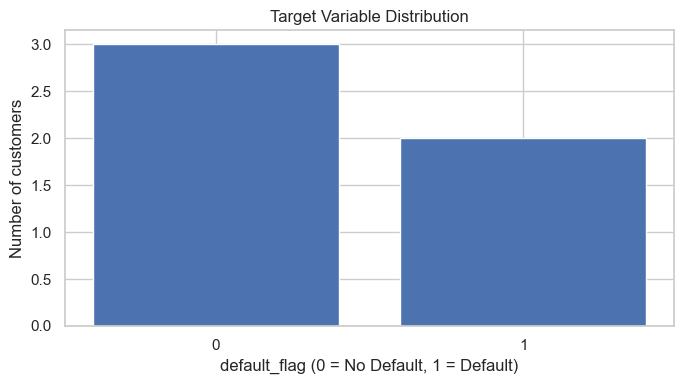

In [12]:
target_counts = df["default_flag"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(target_counts.index.astype(str), target_counts.values)
plt.title("Target Variable Distribution")
plt.xlabel("default_flag (0 = No Default, 1 = Default)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

## 11. Numerical feature distributions

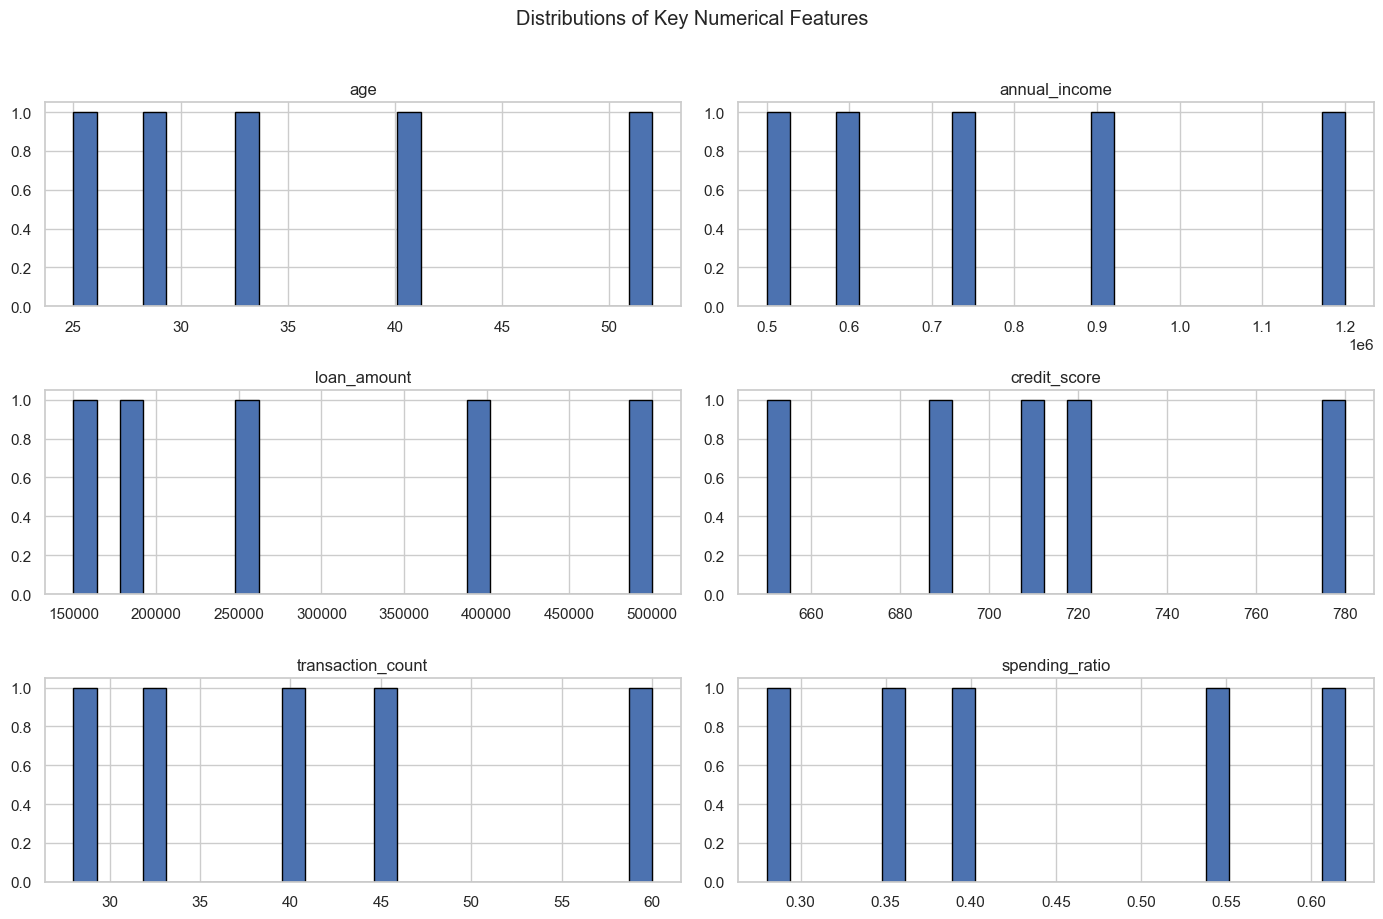

In [13]:
numeric_for_plots = [
    col for col in ["age", "annual_income", "loan_amount", "credit_score",
                    "transaction_count", "spending_ratio"]
    if col in df.columns and pd.api.types.is_numeric_dtype(df[col])
]

if numeric_for_plots:
    df[numeric_for_plots].hist(figsize=(14, 9), bins=25, edgecolor="black")
    plt.suptitle("Distributions of Key Numerical Features", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No expected numerical columns are available for plotting.")

## 12. Categorical feature distributions

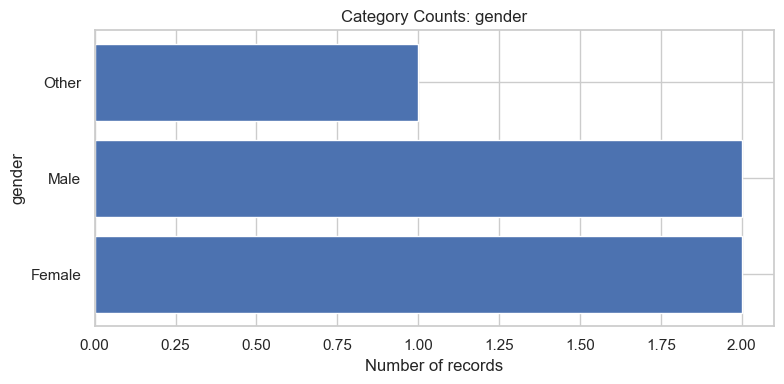

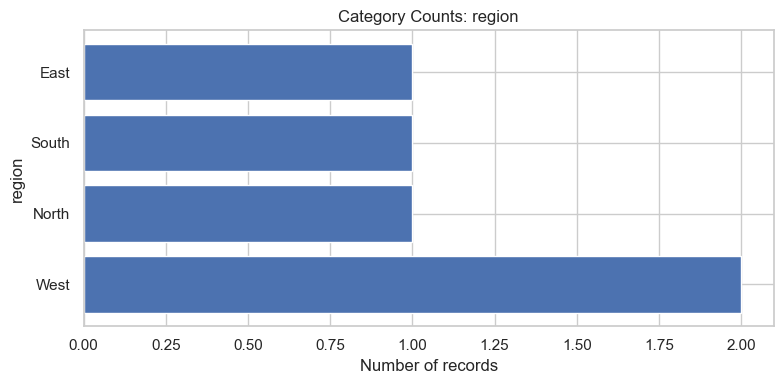

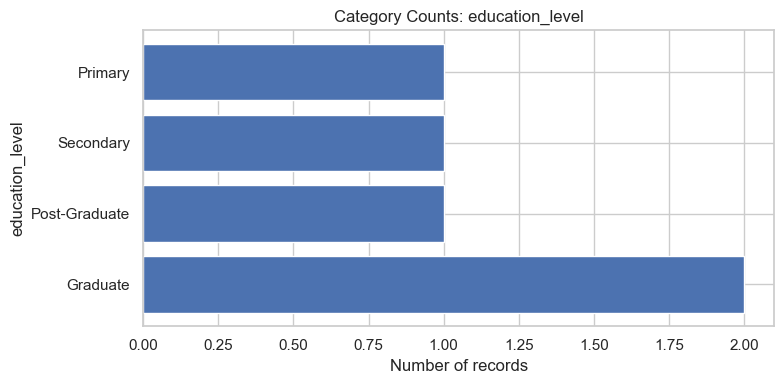

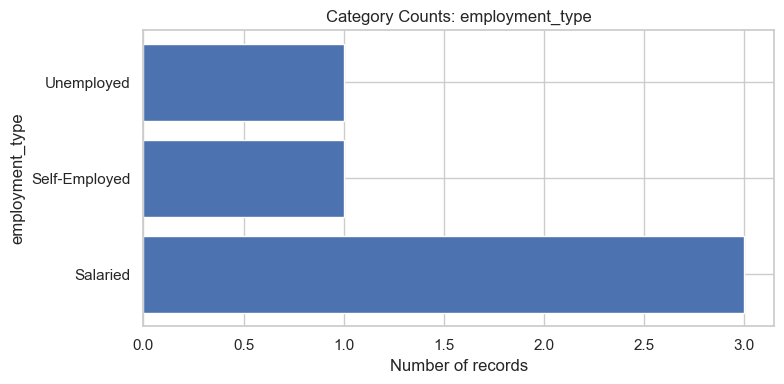

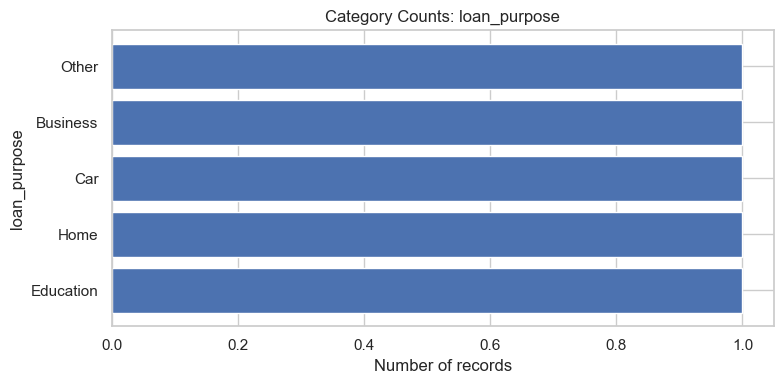

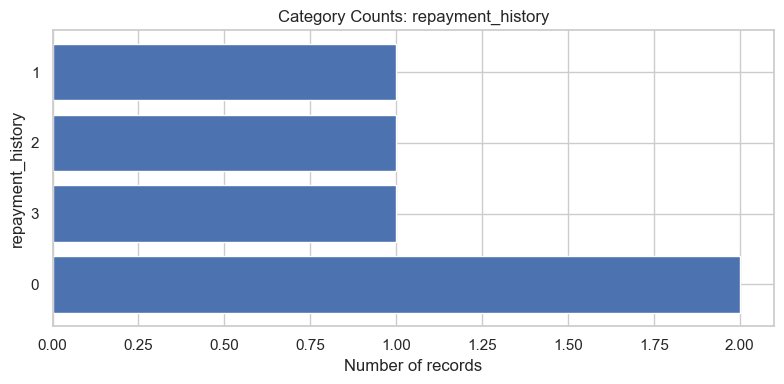

In [14]:
categorical_for_plots = [
    col for col in ["gender", "region", "education_level", "employment_type",
                    "loan_purpose", "repayment_history"]
    if col in df.columns
]

for column in categorical_for_plots:
    counts = df[column].value_counts(dropna=False).head(12)
    plt.figure(figsize=(8, 4))
    plt.barh(counts.index.astype(str), counts.values)
    plt.title(f"Category Counts: {column}")
    plt.xlabel("Number of records")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()

## 13. Correlation analysis for numerical columns

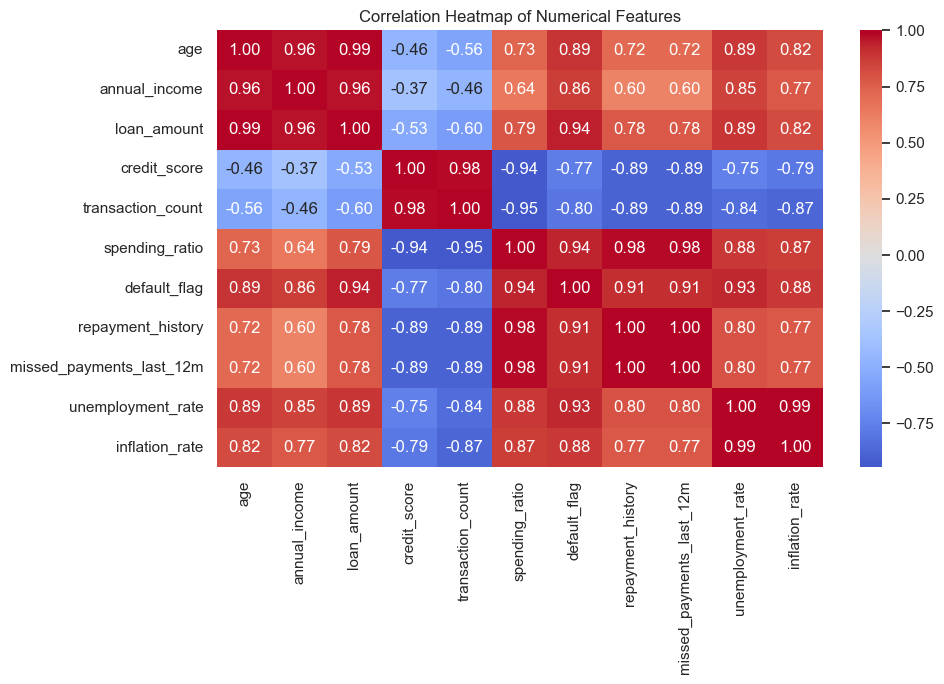

,age,annual_income,loan_amount,credit_score,transaction_count,spending_ratio,default_flag,repayment_history,missed_payments_last_12m,unemployment_rate,inflation_rate
age,1.000000,0.962972,0.989090,-0.461985,-0.563747,0.727877,0.893819,0.715199,0.715199,0.885489,0.817861
annual_income,0.962972,1.000000,0.963836,-0.374033,-0.461095,0.644162,0.863792,0.600123,0.600123,0.848944,0.774046
loan_amount,0.989090,0.963836,1.000000,-0.529049,-0.604845,0.785304,0.940775,0.775011,0.775011,0.891485,0.818763
credit_score,-0.461985,-0.374033,-0.529049,1.000000,0.980065,-0.936593,-0.769800,-0.889297,-0.889297,-0.754337,-0.785825
transaction_count,-0.563747,-0.461095,-0.604845,0.980065,1.000000,-0.945028,-0.801405,-0.887552,-0.887552,-0.840223,-0.874961
spending_ratio,0.727877,0.644162,0.785304,-0.936593,-0.945028,1.000000,0.937143,0.977410,0.977410,0.881780,0.869330
default_flag,0.893819,0.863792,0.940775,-0.769800,-0.801405,0.937143,1.000000,0.910182,0.910182,0.929660,0.880705
repayment_history,0.715199,0.600123,0.775011,-0.889297,-0.887552,0.977410,0.910182,1.000000,1.000000,0.802181,0.773574
missed_payments_last_12m,0.715199,0.600123,0.775011,-0.889297,-0.887552,0.977410,0.910182,1.000000,1.000000,0.802181,0.773574
unemployment_rate,0.885489,0.848944,0.891485,-0.754337,-0.840223,0.881780,0.929660,0.802181,0.802181,1.000000,0.989749


In [15]:
correlation_columns = [
    col for col in numeric_columns
    if col != "customer_id" and df[col].nunique(dropna=True) > 1
]

if len(correlation_columns) >= 2:
    correlation_matrix = df[correlation_columns].corr(numeric_only=True)
    plt.figure(figsize=(10, 7))
    sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", center=0)
    plt.title("Correlation Heatmap of Numerical Features")
    plt.tight_layout()
    plt.show()
    display(correlation_matrix)
else:
    print("Not enough varying numerical columns for a correlation heatmap.")

## 14. Date-column inspection

In [16]:
if "join_date" in df.columns:
    parsed_join_date = pd.to_datetime(df["join_date"], errors="coerce")
    invalid_date_count = int(parsed_join_date.isna().sum())
    print("Unparseable or missing join_date values:", invalid_date_count)
    print("Earliest valid join date:", parsed_join_date.min())
    print("Latest valid join date:", parsed_join_date.max())
else:
    print("The join_date column is not present.")

Unparseable or missing join_date values: 0
Earliest valid join date: 2018-11-05 00:00:00
Latest valid join date: 2023-06-12 00:00:00


## 15. Automated data profiling with ydata-profiling

In [17]:
try:
    from ydata_profiling import ProfileReport

    profile = ProfileReport(
        df,
        title="Customer Credit Risk – Day 02 Data Understanding Report",
        explorative=True,
        minimal=True
    )
    profile_path = REPORTS_DIR / "day_02_ydata_profiling_report.html"
    profile.to_file(profile_path)
    print("Profiling report saved to:", profile_path.resolve())
except ImportError:
    print("ydata-profiling is not installed.")
    print("Install it with: pip install ydata-profiling")
except Exception as error:
    print("The profiling report could not be generated:", repr(error))
    print("Continue with the manual data-quality analysis in this notebook.")

C:\Users\tejpa\AppData\Local\Temp\ipykernel_12388\952268870.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 18/18 [00:00<00:00, 416.09it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\notebooks\reports\day_02_ydata_profiling_report.html


## 16. Data-quality report

In [18]:
quality_rows = []

for column in df.columns:
    quality_rows.append({
        "column": column,
        "data_type": str(df[column].dtype),
        "non_null_count": int(df[column].notna().sum()),
        "missing_count": int(df[column].isna().sum()),
        "missing_percent": round(float(df[column].isna().mean() * 100), 2),
        "unique_count": int(df[column].nunique(dropna=True)
                            ),
        "duplicate_value_count": int(df[column].duplicated().sum())
    })

data_quality_report = pd.DataFrame(quality_rows)
display(data_quality_report)

quality_report_path = REPORTS_DIR / "day_02_data_quality_report.csv"
data_quality_report.to_csv(quality_report_path, index=False)
print("Data-quality report saved to:", quality_report_path.resolve())

,column,data_type,non_null_count,missing_count,missing_percent,unique_count,duplicate_value_count
0,customer_id,object,5,0,0.0,5,0
1,age,int64,5,0,0.0,5,0
2,annual_income,int64,5,0,0.0,5,0
3,loan_amount,int64,5,0,0.0,5,0
4,loan_purpose,object,5,0,0.0,5,0
5,credit_score,int64,5,0,0.0,5,0
6,transaction_count,int64,5,0,0.0,5,0
7,spending_ratio,float64,5,0,0.0,5,0
8,default_flag,int64,5,0,0.0,2,3
9,gender,object,5,0,0.0,3,2


Data-quality report saved to: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\notebooks\reports\day_02_data_quality_report.csv


In [19]:
# Additional dataset-level checks
dataset_summary = pd.DataFrame({
    "metric": [
        "row_count",
        "column_count",
        "fully_duplicated_rows",
        "total_missing_cells",
        "duplicate_customer_ids",
        "data_source_type"
    ],
    "value": [
        len(df),
        df.shape[1],
        int(df.duplicated().sum()),
        int(df.isna().sum().sum()),
        int(df["customer_id"].duplicated().sum()) if "customer_id" in df.columns else "N/A",
        DATA_SOURCE_TYPE
    ]
})
display(dataset_summary)

,metric,value
0,row_count,5
1,column_count,18
2,fully_duplicated_rows,0
3,total_missing_cells,0
4,duplicate_customer_ids,0
5,data_source_type,Institute / previously supplied dataset


## 17. Save a inspection copy

In [20]:
interim_path = INTERIM_DIR / "customer_credit_risk_day02_inspection.csv"
df.to_csv(interim_path, index=False)

print("Inspection copy saved to:", interim_path.resolve())
print("Original raw data was not overwritten.")

Inspection copy saved to: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\notebooks\data\interim\customer_credit_risk_day02_inspection.csv
Original raw data was not overwritten.
